In [1]:
import pandas as pd
import numpy as np
import pickle
import json
import sys
from pathlib import Path
import matplotlib.pyplot as plt
from dataclasses import dataclass
from tqdm.auto import tqdm
import os
from itertools import combinations
import seaborn as sns
import math 
from ssl_neuron.datasets import GraphDataset

sys.path.insert(0, str(Path.cwd().parent))

from analysis_utils import plot_skeletons, plot_random_skeletons_by_type
from utils import plot_random_neurons_by_type
from ssl_neuron.utils import plot_neuron, plot_neurons, compare_augment_plot

In [2]:
import importlib
import ssl_neuron.datasets as datasets

importlib.reload(datasets)

<module 'ssl_neuron.datasets' from '/gpfs01/berens/user/pgivehchian/ssl_neuron/ssl_neuron/datasets.py'>

In [3]:
TRIAL = "trial12"

In [4]:
config = json.load(open(f'../configs/{TRIAL}.json'))
cell_meta = pd.read_csv(os.path.join(config['trainer']['latents_dir'], f'{TRIAL}.csv'))

In [5]:
# Assing the splits
data_dir = config['data']['path']

train_ids = np.load(os.path.join(data_dir, 'train_ids.npy')).astype(str)
val_ids = np.load(os.path.join(data_dir, 'val_ids.npy')).astype(str)
test_ids = np.load(os.path.join(data_dir, 'test_ids.npy')).astype(str)

split_map = {
    **dict.fromkeys(train_ids, 'train'),
    **dict.fromkeys(val_ids, 'val'),
    **dict.fromkeys(test_ids, 'test')
}

cell_meta['split'] = cell_meta['cell_id'].astype(str).map(split_map)
cell_meta = cell_meta.dropna(subset=['split']).reset_index(drop=True)
print(cell_meta['split'].value_counts(dropna=False))

train    1369
val       293
test      293
Name: split, dtype: int64


In [6]:
path = Path(config["data"]["path"]) / "features_pkl.csv"
features_pkl = pd.read_csv(path)

In [7]:
features_pkl["cell"] = features_pkl["cell"].astype(str)
cell_meta["cell_id"] = cell_meta["cell_id"].astype(str)

merged_df = features_pkl.merge(
    cell_meta,
    left_on="cell",
    right_on="cell_id",
    how="left"
)

print(f"Features rows: {len(features_pkl)}")
print(f"Merged rows: {len(merged_df)}")
print(f"Unmatched rows: {merged_df['cell_id'].isna().sum()}")

Features rows: 1959
Merged rows: 1959
Unmatched rows: 0


In [8]:
merged_df.shape

(1959, 489)

## Compare features

In [16]:
def compare_cells(merged_df, selected_ids, features):
    selected_ids = [str(i) for i in selected_ids]

    data = merged_df.copy()
    data["cell_id"] = data["cell_id"].astype(str)
    data = data.set_index("cell_id")

    selected = data.loc[selected_ids, features].apply(pd.to_numeric, errors="coerce")
    X = merged_df[features].apply(pd.to_numeric, errors="coerce")

    X_scaled = (X - X.mean()) / X.std().replace(0, np.nan)
    selected_scaled = X_scaled.loc[data.index.isin(selected_ids)]
    selected_scaled.index = data.index[data.index.isin(selected_ids)]

    scores = pd.DataFrame(index=features)

    for a, b in combinations(selected_ids, 2):
        scores[f"{a}_vs_{b}"] = (selected_scaled.loc[a] - selected_scaled.loc[b]).abs()

    for cell_id in selected_ids:
        scores[f"{cell_id}_value"] = selected.loc[cell_id]
        scores[f"{cell_id}_zscore"] = (selected.loc[cell_id] - X.mean()) / X.std()

    pairwise_cols = [f"{a}_vs_{b}" for a, b in combinations(selected_ids, 2)]
    scores["average_pairwise_difference"] = scores[pairwise_cols].mean(axis=1)

    return scores.sort_values("average_pairwise_difference")

In [9]:
selected_ids = ["720575940569530957", "720575940572449537"]

features = [
    "total_length",
    "n_nodes_raw",
    "branch_points",
    "tips",
    "stems",
    "tree_asymmetry",
    "width",
    "depth",
    "height",
    "branch_angle_mean",
    "path_angle_mean",
    "tortuosity_mean",
    "radius_mean",
    "soma_z",
    "perc_z_050_1",
    "w_l0_1",
    "w_l1_1",
    "w_l2_1"
]

compare_cells(merged_df, selected_ids, features)

,720575940569530957_vs_720575940572449537,720575940569530957_value,720575940569530957_zscore,720575940572449537_value,720575940572449537_zscore,average_pairwise_difference
branch_angle_mean,0.063951,90.397600,-0.819397,90.761500,-0.755447,0.063951
tree_asymmetry,0.136709,0.843509,-0.702701,0.847402,-0.565992,0.136709
depth,0.223247,202.914000,-1.249634,259.346000,-1.026388,0.223247
radius_mean,0.247346,0.247733,-0.597692,0.260411,-0.350347,0.247346
width,0.285503,198.449000,0.311725,183.141000,0.026221,0.285503
perc_z_050_1,0.552529,16.471000,1.181285,20.417600,1.733815,0.552529
height,0.617266,37.921400,-0.562300,42.823900,0.054966,0.617266
branch_points,0.714514,347.000000,-0.226814,253.000000,-0.941328,0.714514
tips,0.738160,361.000000,-0.247775,259.000000,-0.985935,0.738160
path_angle_mean,0.738407,19.123400,0.132852,17.349700,-0.605555,0.738407


In [17]:
def compare_celltypes(merged_df, features, celltypes):

    X = merged_df[features].apply(pd.to_numeric, errors="coerce")

    global_mean = X.mean()
    global_std = X.std().replace(0, np.nan)
    means = X.groupby(merged_df["celltype_final"]).mean()
    means_selected = means.loc[celltypes]
    means_scaled = (means_selected - global_mean) / global_std
    comparison_scores = pd.DataFrame(index=features)

    for celltype in celltypes:
        comparison_scores[f"{celltype}_mean"] = means_selected.loc[celltype]
        comparison_scores[f"{celltype}_zscore"] = means_scaled.loc[celltype]

    pairwise_cols = []

    for celltype_1, celltype_2 in combinations(celltypes, 2):
        col_name = f"{celltype_1}_vs_{celltype_2}"

        comparison_scores[col_name] = (
            means_scaled.loc[celltype_1] -
            means_scaled.loc[celltype_2]
        ).abs()

        pairwise_cols.append(col_name)

    comparison_scores["average_pairwise_difference"] = (
        comparison_scores[pairwise_cols].mean(axis=1)
    )

    comparison_scores = comparison_scores.sort_values(
        "average_pairwise_difference"
    )

    return comparison_scores

In [18]:
celltypes = ["OFF medium sustained", "OFF sustained EW1no", "ON small OFF large"]

In [19]:
compare_celltypes(merged_df, features, celltypes)

,OFF medium sustained_mean,OFF medium sustained_zscore,OFF sustained EW1no_mean,OFF sustained EW1no_zscore,ON small OFF large_mean,ON small OFF large_zscore,OFF medium sustained_vs_OFF sustained EW1no,OFF medium sustained_vs_ON small OFF large,OFF sustained EW1no_vs_ON small OFF large,average_pairwise_difference
branch_points,295.000000,-0.622077,280.584906,-0.731649,298.833333,-0.592939,0.109572,0.029138,0.138710,0.092473
tips,307.288462,-0.636478,291.622642,-0.749849,311.916667,-0.602984,0.113371,0.033494,0.146865,0.097910
soma_z,-13.725094,0.229323,-14.417308,-0.003310,-13.674861,0.246205,0.232633,0.016882,0.249515,0.166344
height,47.090383,0.592152,48.222143,0.734650,46.205675,0.480760,0.142498,0.111392,0.253890,0.169260
n_nodes_raw,12372.173077,0.244442,11223.169811,-0.012183,11859.750000,0.129995,0.256625,0.114448,0.142178,0.171084
depth,565.263192,0.183830,535.824811,0.067371,489.708833,-0.115066,0.116459,0.298895,0.182436,0.199263
width,188.148731,0.119618,206.425717,0.460495,204.531667,0.425170,0.340877,0.305552,0.035325,0.227251
radius_mean,0.275882,-0.048510,0.264428,-0.271981,0.255272,-0.450608,0.223471,0.402097,0.178627,0.268065
path_angle_mean,17.304169,-0.624510,18.310896,-0.205401,17.525692,-0.532288,0.419109,0.092222,0.326888,0.279406
tortuosity_mean,1.128541,-0.415687,1.137921,0.142334,1.131204,-0.257261,0.558022,0.158426,0.399596,0.372014


In [20]:
def plot_feature_distributions(merged_df, features, celltypes):

    sns.set_theme(style="white", context="notebook")
    palette = dict(zip(celltypes, sns.color_palette("deep", len(celltypes))))

    data = merged_df[merged_df["celltype_final"].isin(celltypes)].copy()
    nrows = math.ceil(len(features) / 4)

    fig, axes = plt.subplots(nrows, 4, figsize=(18, 3.5 * nrows))
    axes = np.array(axes).flatten()

    for ax, feature in zip(axes, features):
        data[feature] = pd.to_numeric(data[feature], errors="coerce")
        mean = pd.to_numeric(merged_df[feature], errors="coerce").mean()

        sns.violinplot(
            data=data, x="celltype_final", y=feature,
            hue="celltype_final", order=celltypes, palette=palette,
            inner="box", cut=0, linewidth=0.8, legend=False, ax=ax
        )

        ax.axhline(mean, color="#444444", ls="--", lw=1,
                   label=f"Global mean: {mean:.2f}")
        ax.set(title=feature.replace("_", " "), xlabel="", ylabel="")
        ax.tick_params(axis="x", rotation=25, labelsize=8)
        ax.grid(axis="y", color="#E9E8E5", linewidth=0.7)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(frameon=False, fontsize=8)

    for ax in axes[len(features):]:
        ax.remove()

    fig.suptitle("Morphological feature distributions",
                 fontsize=17, fontweight="semibold", y=1.01)
    plt.tight_layout()
    plt.show()

In [21]:
features_top = [
    "branch_points",
    "tips",
    "soma_z",
    "height",
    "n_nodes_raw",
    "depth",
    "width",
    "radius_mean",
    "path_angle_mean",
    "tortuosity_mean",
    "perc_z_050_1",
    "stems",
    "branch_angle_mean",
    "total_length",
    "tree_asymmetry"
]

In [12]:
def plot_feature_distributions(merged_df, features, celltypes, standardized=False):
    sns.set_theme(style="white", context="notebook")
    palette = dict(zip(celltypes, sns.color_palette("deep", len(celltypes))))

    data = merged_df[merged_df["celltype_final"].isin(celltypes)].copy()
    nrows = math.ceil(len(features) / 4)
    fig, axes = plt.subplots(nrows, 4, figsize=(18, 3.5 * nrows))
    axes = np.array(axes).flatten()

    for ax, feature in zip(axes, features):
        values = pd.to_numeric(merged_df[feature], errors="coerce")
        mean, std = values.mean(), values.std()

        data[feature] = pd.to_numeric(data[feature], errors="coerce")
        if standardized:
            data[feature] = (data[feature] - mean) / std

        sns.violinplot(
            data=data, x="celltype_final", y=feature,
            hue="celltype_final", order=celltypes, palette=palette,
            inner="box", cut=0, linewidth=0.8, legend=False, ax=ax
        )

        ax.axhline(0 if standardized else mean, color="#444444",
                   ls="--", lw=1, label="Global mean")
        ax.set(title=feature.replace("_", " "), xlabel="",
               ylabel="Standardized value" if standardized else "")
        ax.tick_params(axis="x", rotation=25, labelsize=8)
        ax.grid(axis="y", color="#E9E8E5", linewidth=0.7)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.legend(frameon=False, fontsize=8)

    for ax in axes[len(features):]:
        ax.remove()

    fig.suptitle("Morphological feature distributions",
                 fontsize=17, fontweight="semibold", y=1.01)
    plt.tight_layout()
    plt.show()

In [18]:
features = [
    # Overall morphology and size
    "total_length",
    "total_surface",
    "total_volume",
    "width",
    "depth",
    "height",
    "hull_diameter",
    "hull_area",
    "hull_perimeter",
    "ipl_hull_diameter",

    # Branching complexity
    "branch_points",
    "tips",
    "stems",
    "n_nodes_raw",
    "max_branch_order",
    "tree_asymmetry",
    "max_segment_path_length",
    "median_intermediate_segment_pl",
    "median_terminal_segment_pl",

    # Branching and neurite geometry
    "branch_angle_mean",
    "branch_angle_std",
    "branch_angle_q5",
    "branch_angle_q95",
    "path_angle_mean",
    "path_angle_std",
    "path_angle_q5",
    "path_angle_q95",
    "mean_soma_exit_angle",

    # Tortuosity and neurite shape
    "tortuosity_mean",
    "tortuosity_std",
    "tortuosity_q5",
    "tortuosity_q95",
    "xy_excess_path_mean",
    "z_excess_path_mean",
    "wavy_excess_mean",
    "wavy_band_rms_xy",
    "wavy_band_rms_z",

    # Neurite radius
    "radius_mean",
    "radius_std",
    "radius_q5",
    "radius_q95",

    # Soma position and stratification
    "soma_x_um",
    "soma_y_um",
    "soma_z_um",
    "soma_rad_um",
    "perc_z_002_1",
    "perc_z_005_1",
    "perc_z_025_1",
    "perc_z_050_1",
    "perc_z_075_1",
    "perc_z_095_1",
    "perc_z_098_1",

    # IPL layer distribution
    "w_l0_1",
    "w_l1_1",
    "w_l2_1",
    "w_l3_1",
    "w_l4_1",
    "w_l5_1",
    "w_l6_1",
    "w_l7_1",
    "w_l8_1",
    "w_l9_1",
    "w_lx_1",
    "w_ly_1",
    "w_lz_1",

    # Spatial extent of dendritic arbor
    "on_hull_diameter",
    "off_hull_diameter",
    "on_hull_area",
    "off_hull_area",
    "n_dendrite_tips",

    # Asymmetry
    "asym_total_length_um",
    "asym_n_eff",
    "asym_c1",
    "asym_c2",
    "asym_bipolar",
    "asym_c1_debiased",
    "asym_c2_debiased",
    "asym_lean_angle_deg",
    "asym_axis_angle_deg"
]

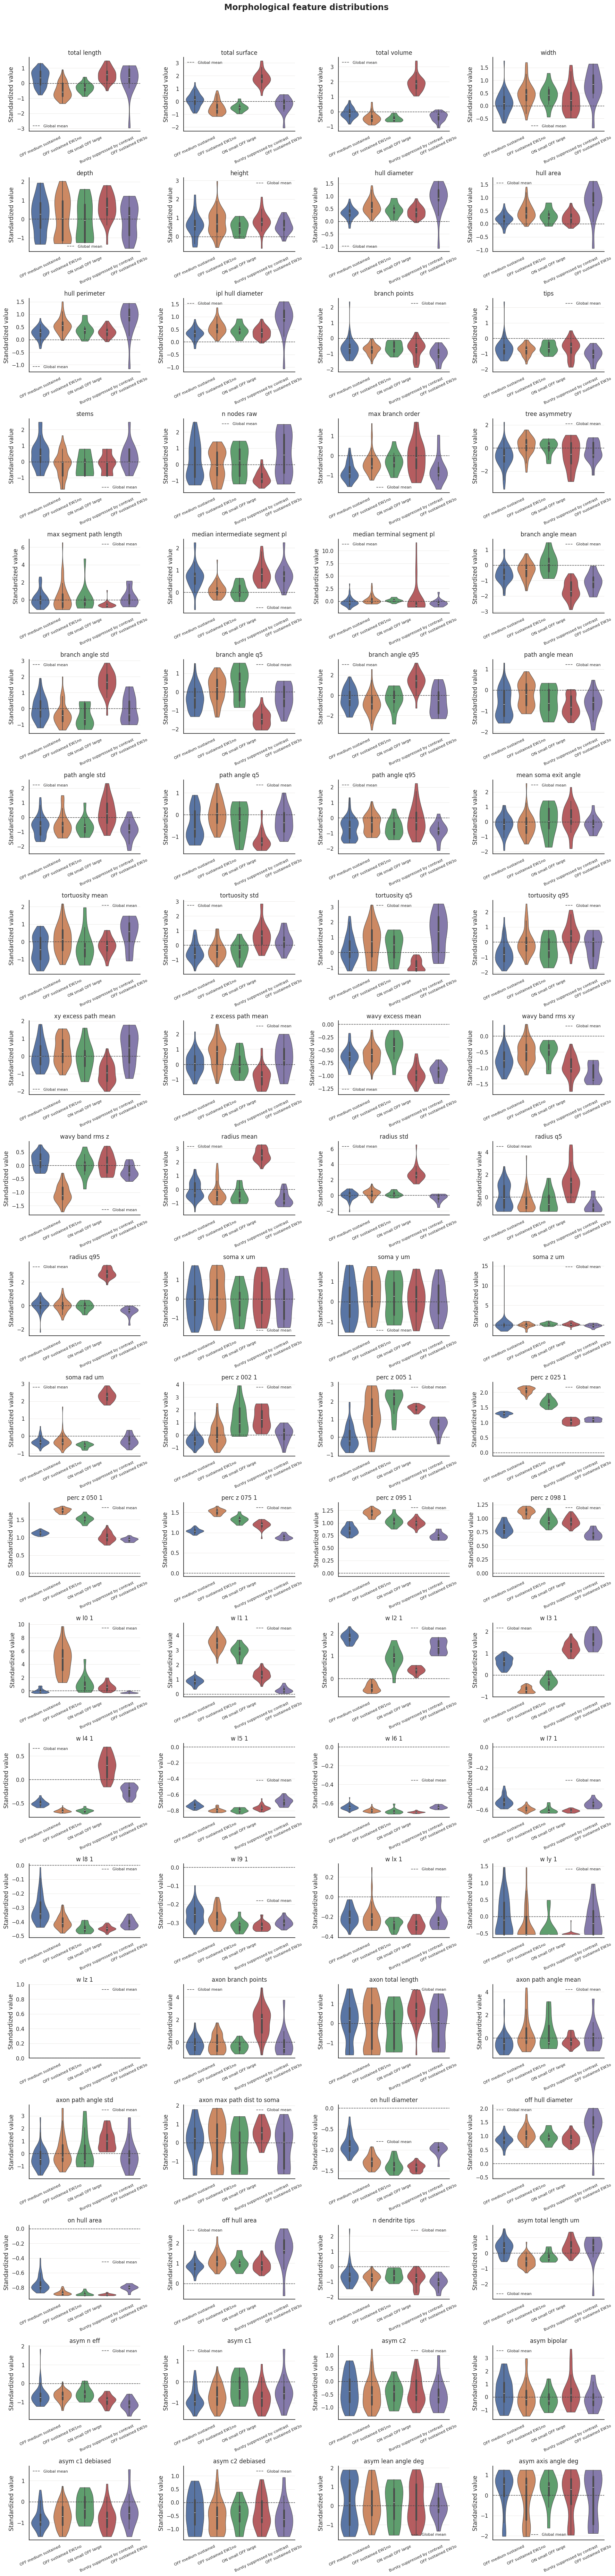

In [66]:
plot_feature_distributions(
    merged_df,
    features= features,
    celltypes=[
        "OFF medium sustained",
        "OFF sustained EW1no",
        "ON small OFF large",
        "Bursty suppressed by contrast",
        "OFF sustained EW3o"
    ],
    standardized=True
)

#### Local Edge Detector VS UHD

In [10]:
celltypes=['UHD', 'Local edge detector']

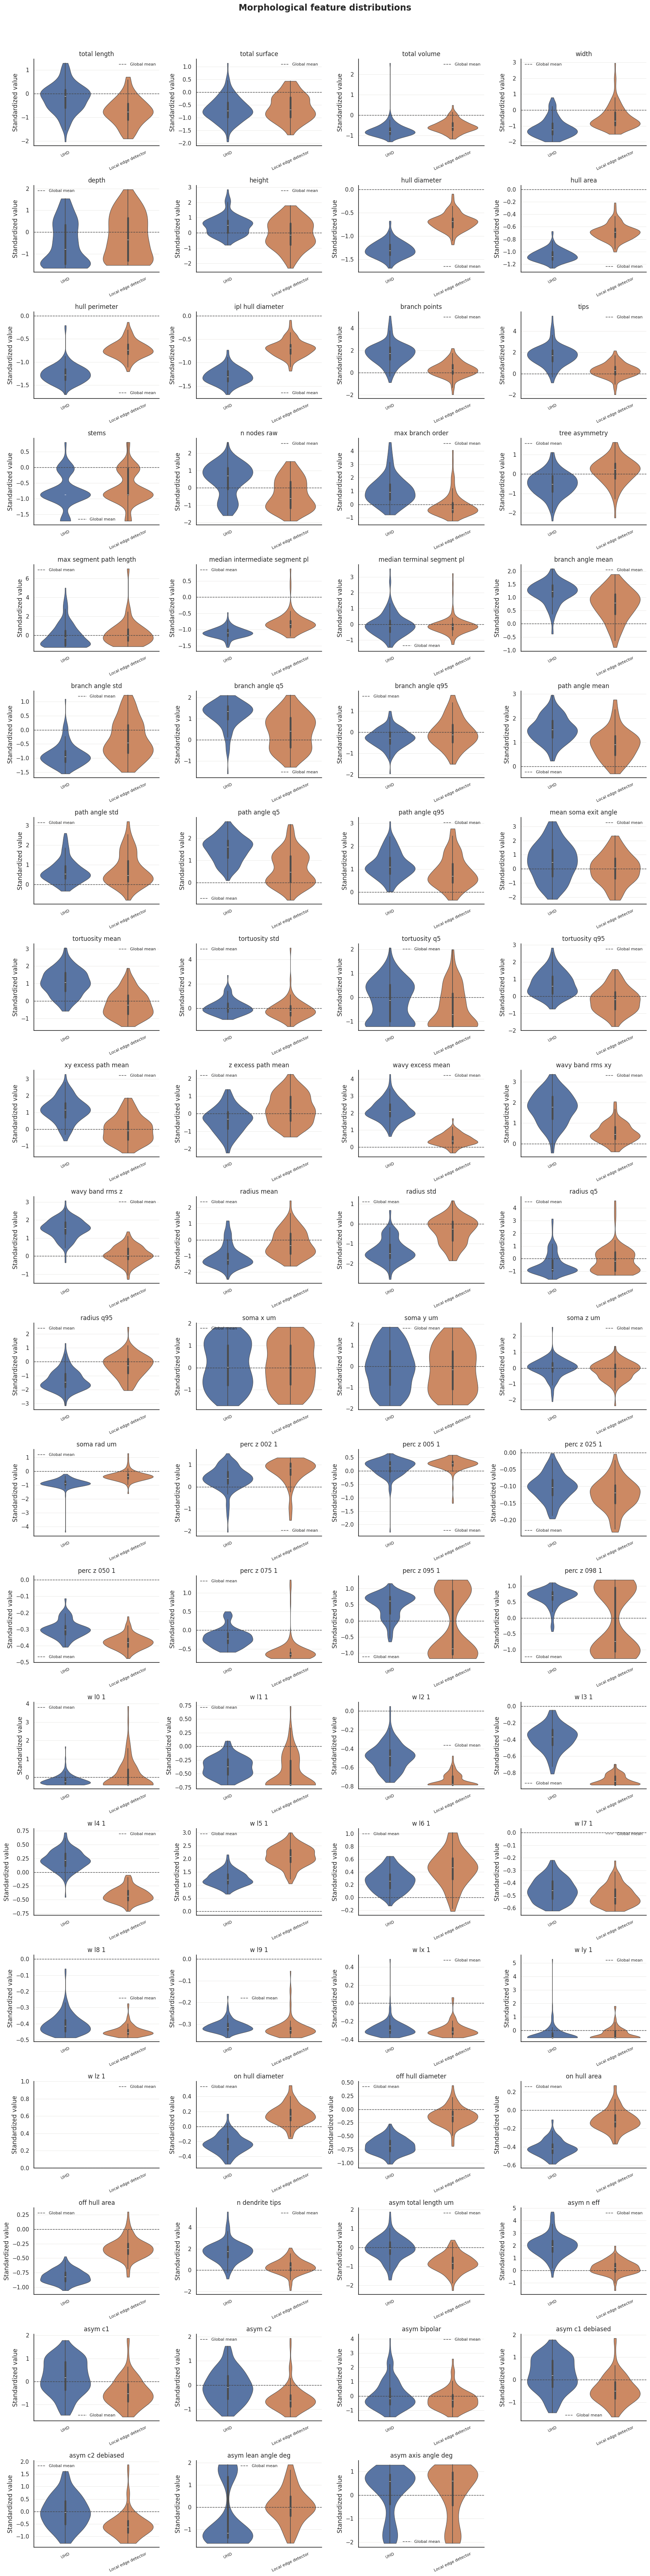

In [19]:
plot_feature_distributions(
    merged_df,
    features= features,
    celltypes=celltypes,
    standardized=True
)

In [21]:
scores = compare_celltypes(merged_df, features, celltypes)

In [26]:
scores.tail(10)

,UHD_mean,UHD_zscore,Local edge detector_mean,Local edge detector_zscore,UHD_vs_Local edge detector,average_pairwise_difference
xy_excess_path_mean,0.100290,1.161181,0.078601,0.006554,1.154626,1.154626
wavy_band_rms_xy,1.126446,1.727540,0.973340,0.519524,1.208016,1.208016
tortuosity_mean,1.153403,1.063482,1.132549,-0.177274,1.240756,1.240756
tips,630.516340,1.702678,437.250000,0.304036,1.398642,1.398642
n_dendrite_tips,619.496732,1.738469,426.180000,0.332264,1.406205,1.406205
wavy_band_rms_z,0.649218,1.512036,0.519637,0.080998,1.431038,1.431038
branch_points,602.379085,1.714376,413.360000,0.277602,1.436774,1.436774
wavy_excess_mean,0.161932,2.155671,0.105136,0.432629,1.723041,1.723041
asym_n_eff,620.313634,1.975961,367.261782,0.246785,1.729176,1.729176
w_lz_1,0.000000,NaN,0.000000,NaN,NaN,NaN


In [30]:
bottom_features = scores.tail(10).index
top_features = scores.head(10).index

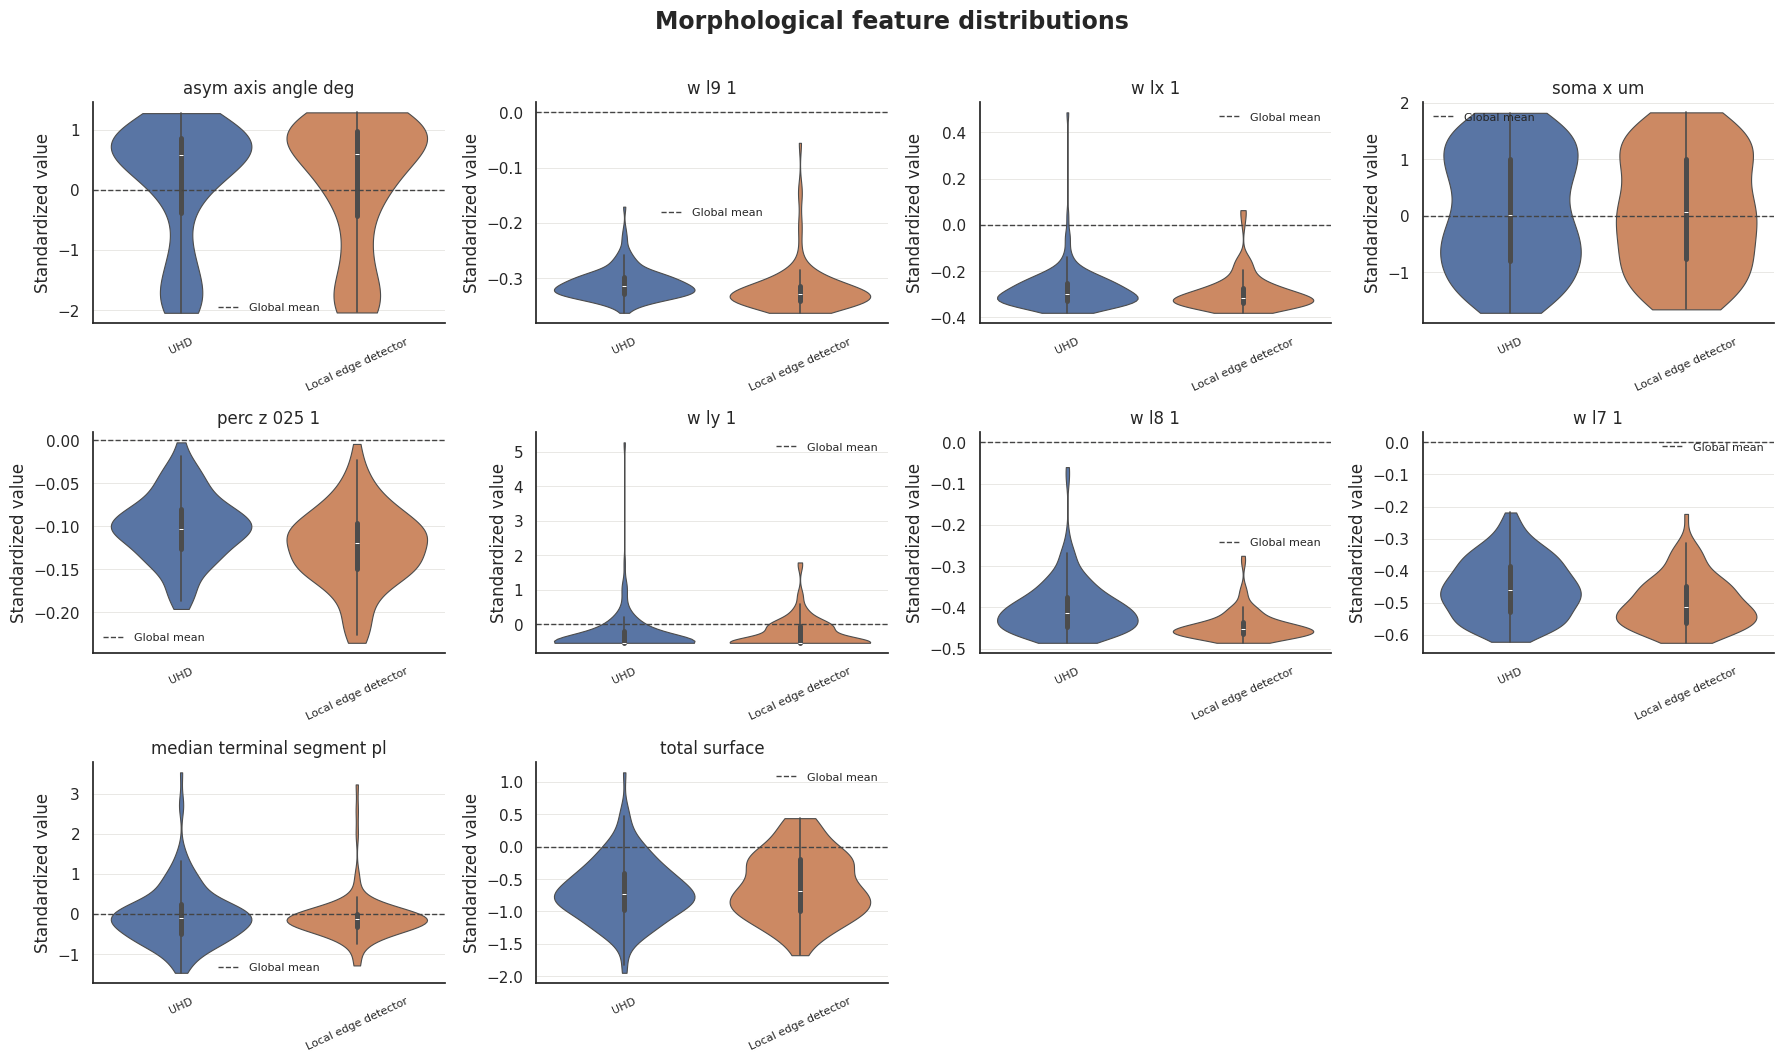

In [31]:
plot_feature_distributions(
    merged_df,
    features= top_features,
    celltypes=celltypes,
    standardized=True
)

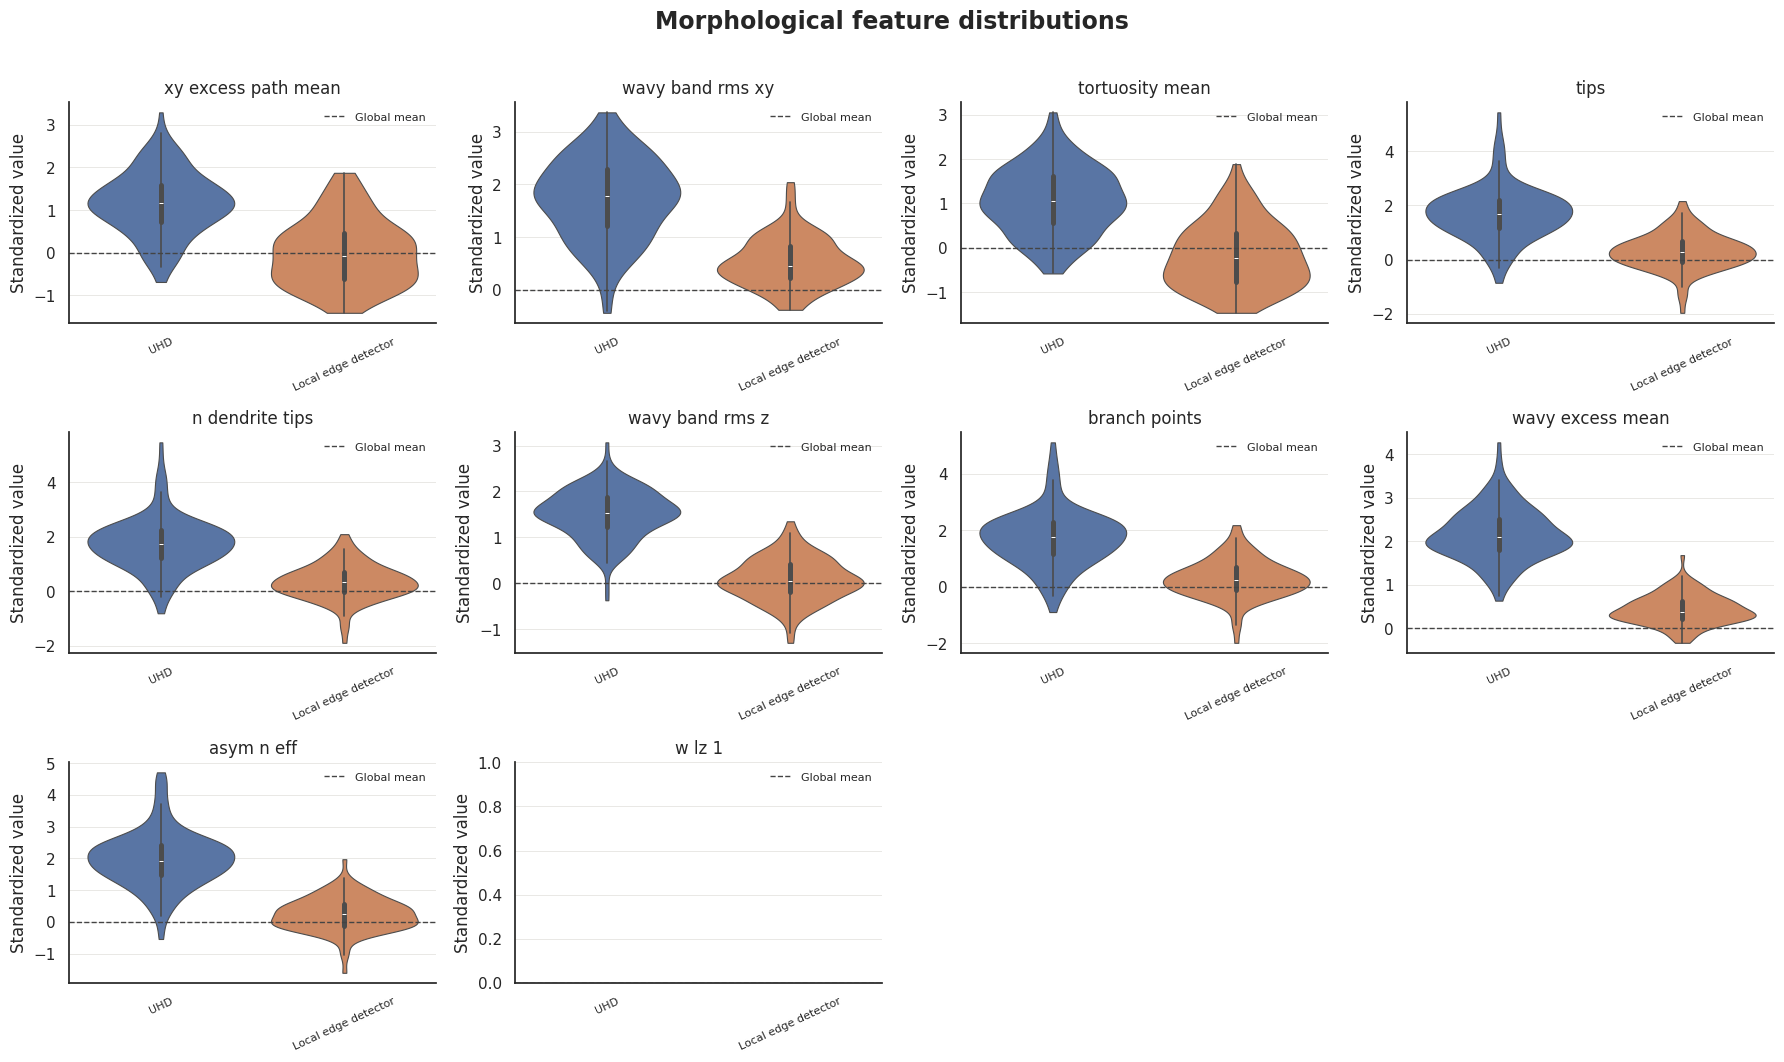

In [29]:
plot_feature_distributions(
    merged_df,
    features= features,
    celltypes=celltypes,
    standardized=True
)

## Load Skeletons

Here I load the full skeletons (not the downsampled ones from the dataloader)

In [22]:
split_ids = set(train_ids) | set(val_ids) | set(test_ids)

In [41]:
@dataclass
class Skeleton:
    features: np.ndarray
    # projections: object
    neighbors: dict


skeletons_path = Path(config['data']['path']) / "skeletons"
data_path = Path(config['data']['path'])

skeletons = {}

for cell_dir in tqdm(skeletons_path.iterdir(), desc="Loading skeletons", unit="cell"):

    if not cell_dir.is_dir():
        continue

    cell_id = cell_dir.name

    if cell_id not in split_ids:
        continue
    
    try:
        features = np.load(cell_dir / "features.npy")

        with open(cell_dir / "neighbors.pkl", "rb") as f:
            neighbors = pickle.load(f)

        # projections_path = cell_dir / "projections.npy"
        # if projections_path.exists():
        #     projections = np.load(projections_path)
        # else:
        #     projections = np.nan

        skeletons[cell_id] = Skeleton(
            features=features,
            # projections=projections,
            neighbors=neighbors
        )

    except Exception as e:
        print(f"ERROR for {cell_id}: {type(e).__name__}: {e}")

print(f"Loaded {len(skeletons)} cells")

Loading skeletons: 0cell [00:00, ?cell/s]

Loaded 1955 cells


## Plot full skeletons

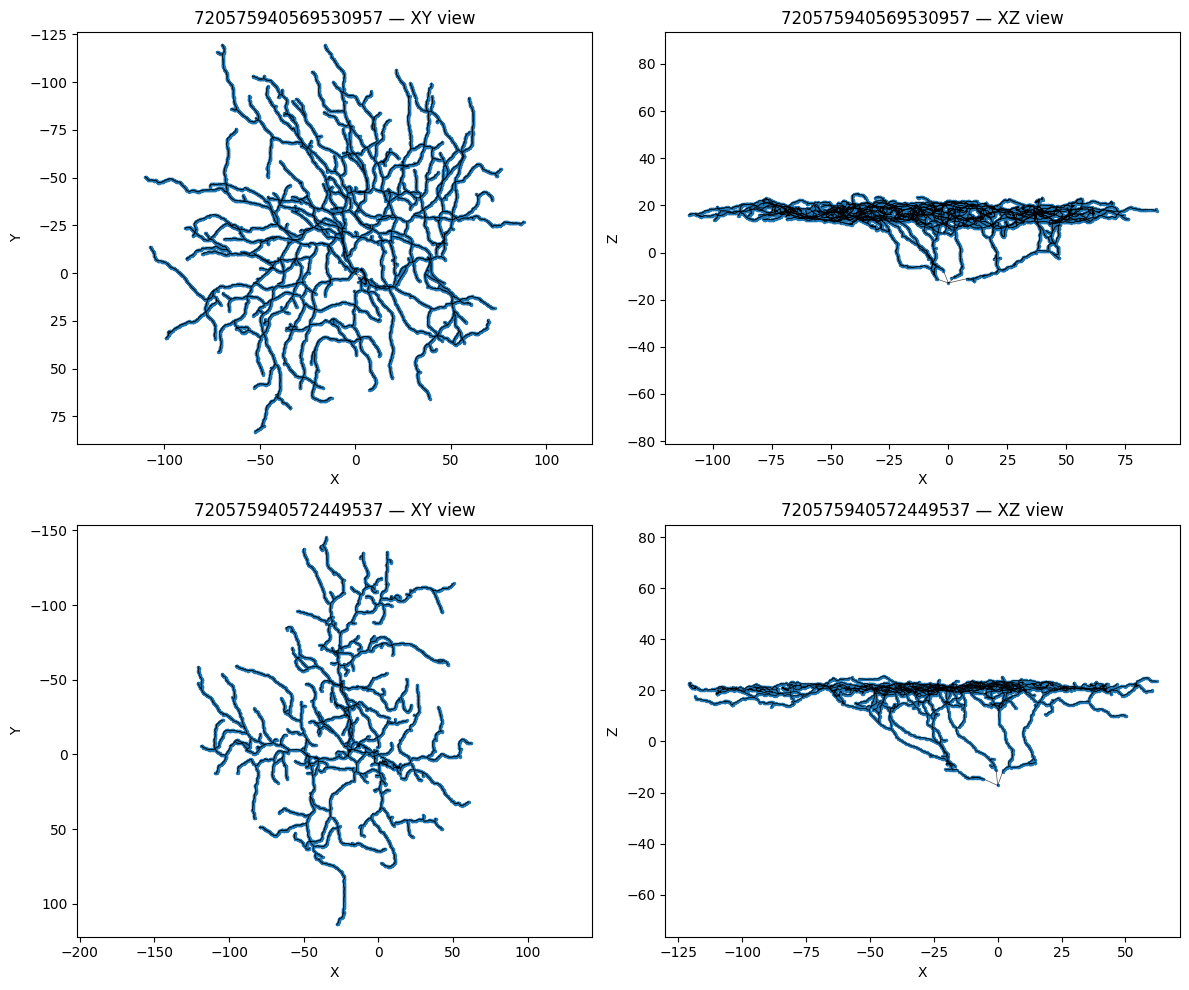

In [9]:
cell_ids = [
    "720575940569530957",
    "720575940572449537",
]

selected_skeletons = [skeletons[cell_id] for cell_id in cell_ids]

plot_skeletons(selected_skeletons, titles=cell_ids)

## Analysing overlapping clusters

In [17]:
overlapping_types = [
    "OFF sustained EW1no",
    "OFF sustained alpha",
    "OFF sustained EW3o",
    "ON bursty",
    "Bursty suppressed by contrast"
]

In [ ]:
on_bursty = cell_meta[cell_meta["celltype_final"] == "ON bursty"]
off_sus_alpha = cell_meta[cell_meta["celltype_final"] == "OFF sustained alpha"]

In [24]:
# plot_random_skeletons_by_type(
#     cell_meta=cell_meta,
#     skeletons=skeletons,
#     cell_types=overlapping_types,
#     n_samples=5,
#     random_state=42
# )

## Plot Augmentations

In [9]:
import importlib
import ssl_neuron.datasets as datasets

importlib.reload(datasets)

<module 'ssl_neuron.datasets' from '/gpfs01/berens/user/pgivehchian/ssl_neuron/ssl_neuron/datasets.py'>

In [31]:
import importlib
import ssl_neuron.utils as utils
from ssl_neuron.utils import plot_neurons, compare_augment_plot
importlib.reload(utils)

<module 'ssl_neuron.utils' from '/gpfs01/berens/user/pgivehchian/ssl_neuron/ssl_neuron/utils.py'>

## Compare augmentations

### Test 1

cache nodes = 3000

In [ ]:
TRIAL = "trial12"
TEST = "test1"
config = json.load(open(f'../configs/{TEST}.json'))
# cell_meta = pd.read_csv(os.path.join(config['trainer']['latents_dir'], f'{TRIAL}.csv'))

# # Assing the splits
# data_dir = config['data']['path']

# train_ids = np.load(os.path.join(data_dir, 'train_ids.npy')).astype(str)
# val_ids = np.load(os.path.join(data_dir, 'val_ids.npy')).astype(str)
# test_ids = np.load(os.path.join(data_dir, 'test_ids.npy')).astype(str)

# split_map = {
#     **dict.fromkeys(train_ids, 'train'),
#     **dict.fromkeys(val_ids, 'val'),
#     **dict.fromkeys(test_ids, 'test')
# }

# cell_meta['split'] = cell_meta['cell_id'].astype(str).map(split_map)
# cell_meta = cell_meta.dropna(subset=['split']).reset_index(drop=True)
# print(cell_meta['split'].value_counts(dropna=False))

train    1369
val       293
test      293
Name: split, dtype: int64


In [ ]:
dset = GraphDataset(config, mode='all')

  1%|          | 15/1955 [00:01<03:52,  8.34it/s]

100%|██████████| 1955/1955 [03:31<00:00,  9.23it/s]


UHD - LED - OFF transient small RF - HD2

unaugmented (These cells were closely located)

Cell 720575940580612789: features shape=(3000, 3), nodes=3000
Cell 720575940570359861: features shape=(3000, 3), nodes=3000
Cell 720575940571250875: features shape=(3000, 3), nodes=3000
Cell 720575940578764234: features shape=(3000, 3), nodes=3000


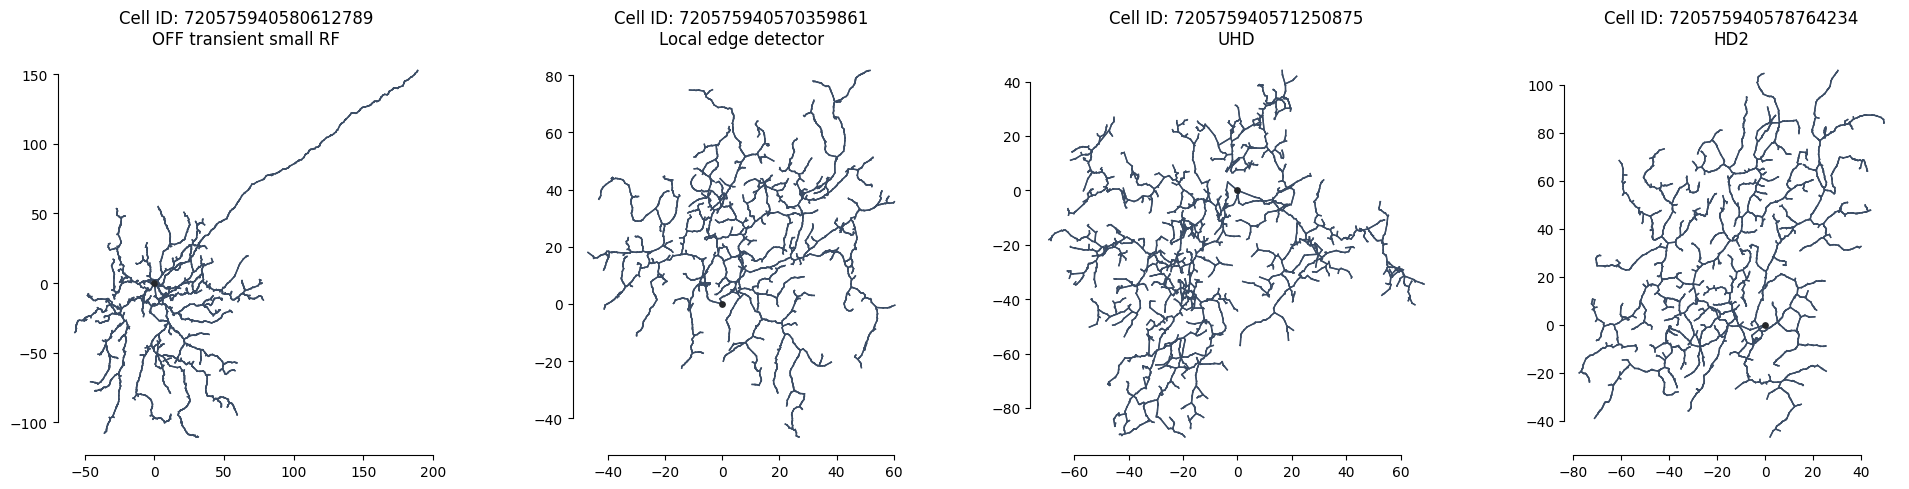

In [20]:
cell_ids = [
    720575940580612789,
    720575940570359861,
    720575940571250875,
    720575940578764234
]
fig, axes = plot_neurons(dset, cell_ids, merged_df)

augmented

Cell 720575940580612789: features shape=(512, 3), nodes=512
Cell 720575940570359861: features shape=(512, 3), nodes=512
Cell 720575940571250875: features shape=(512, 3), nodes=512
Cell 720575940578764234: features shape=(512, 3), nodes=512


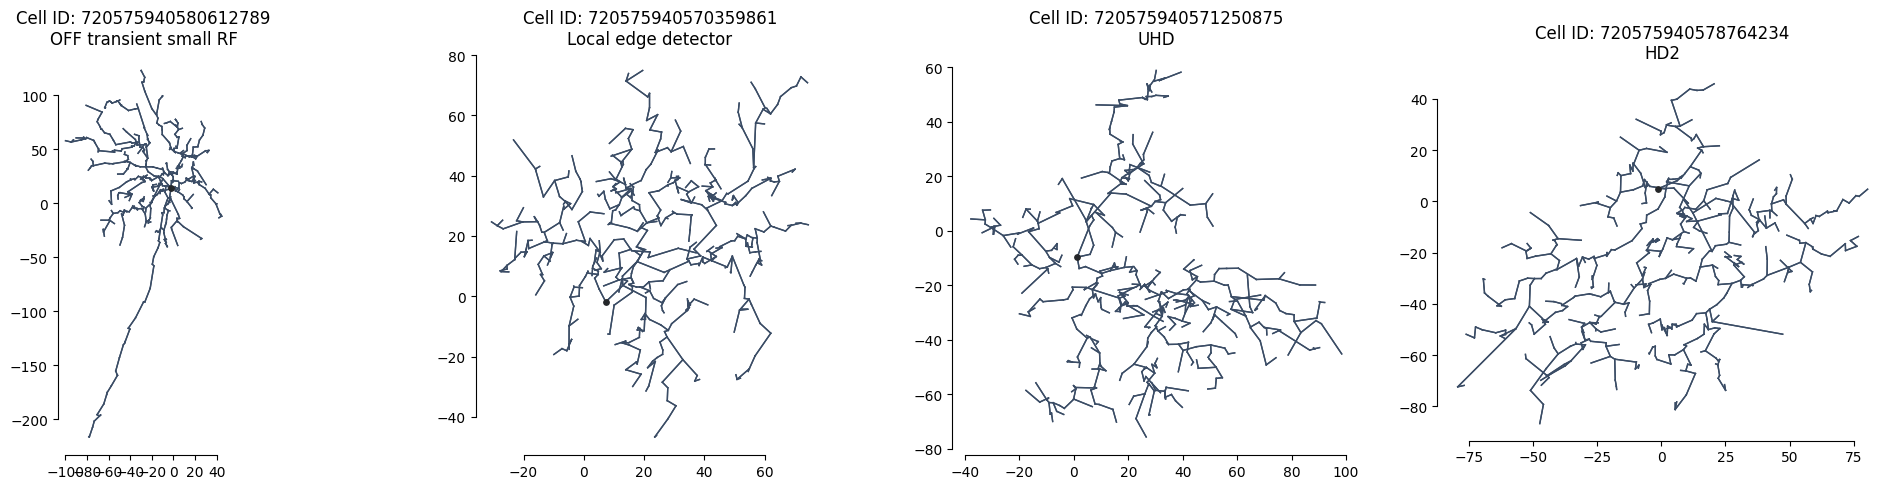

In [21]:
fig, axes = plot_neurons(dset, cell_ids, merged_df, augment=True)

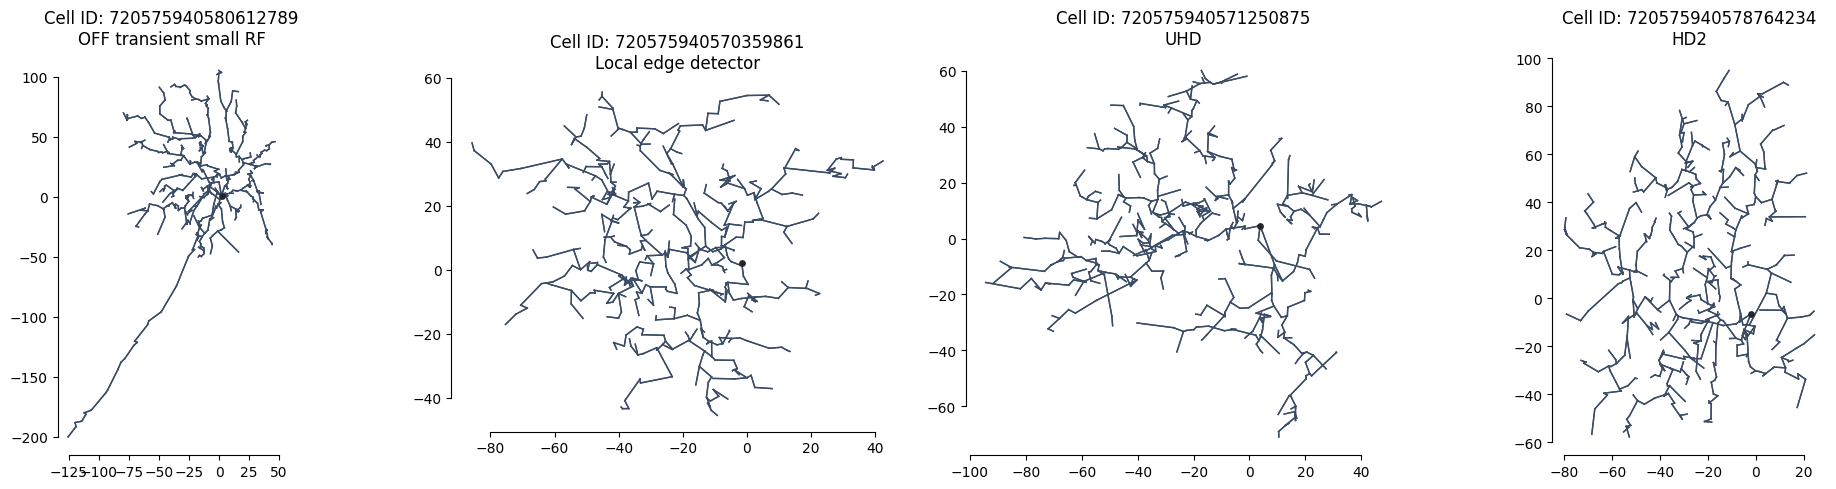

In [15]:
fig, axes = plot_neurons(dset, cell_ids, merged_df, augment=True)

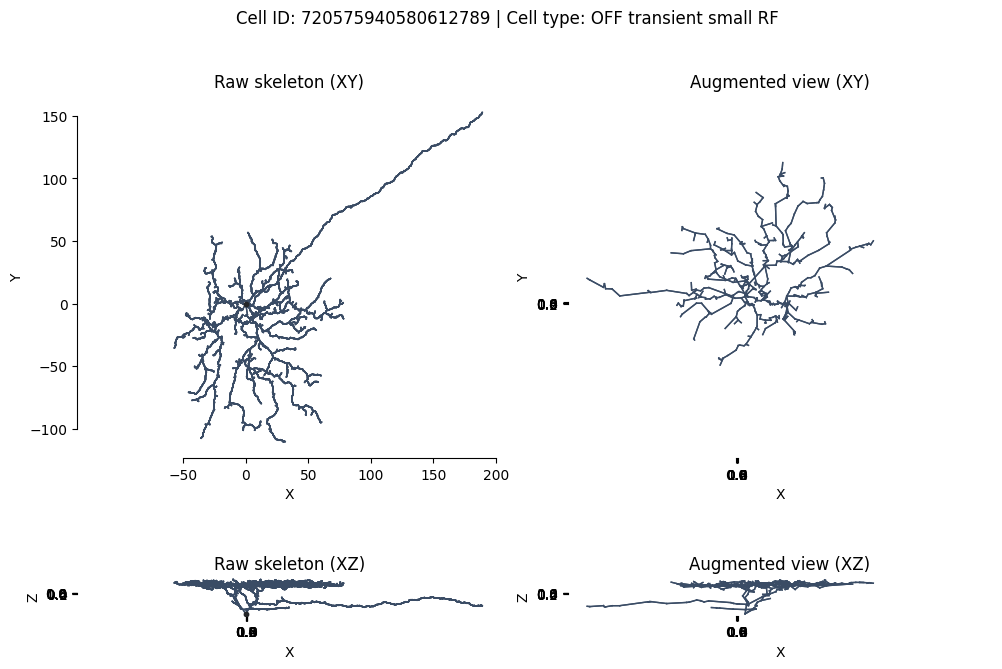

In [37]:
fig, axes = compare_augment_plot('720575940580612789', dset, merged_df)

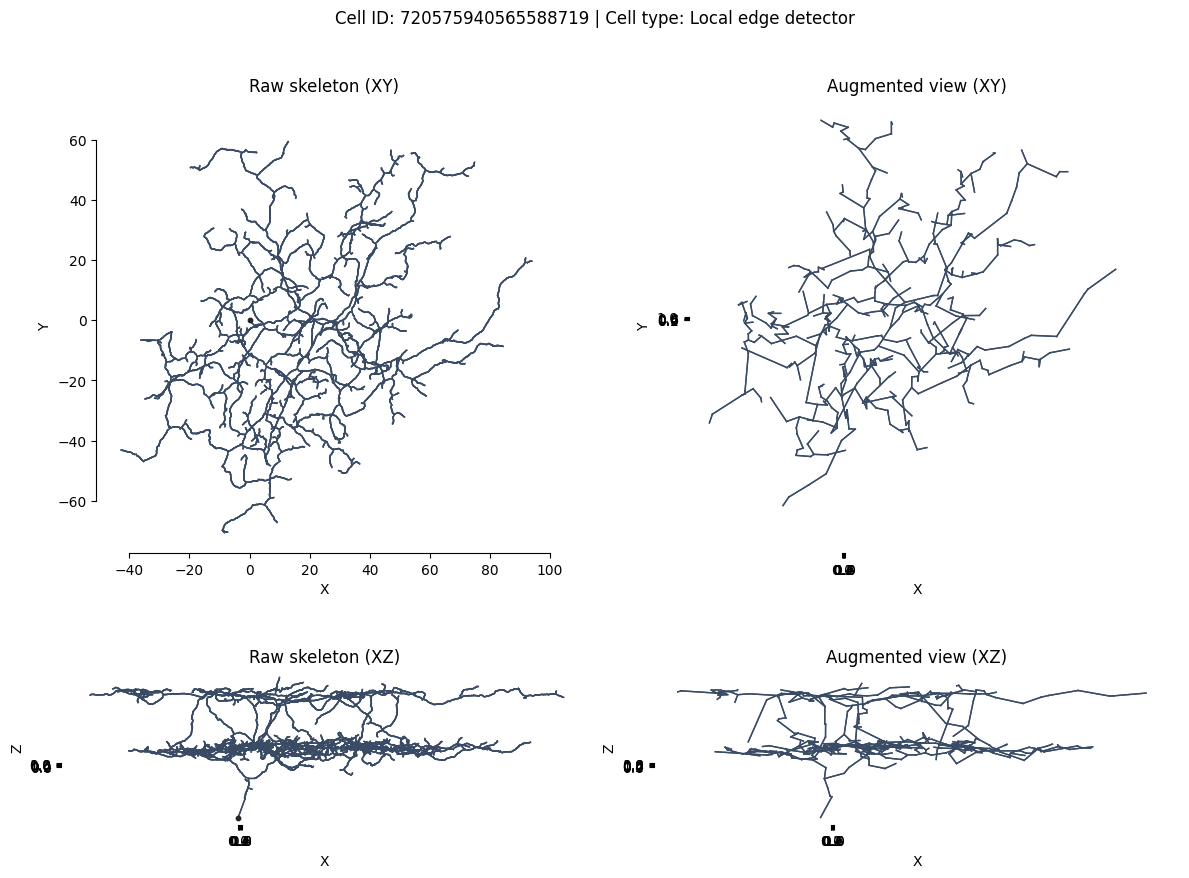

In [13]:
fig, axes = compare_augment_plot('720575940565588719', dset, merged_df)

### Test 2

n_drop_branch: 20 <br>
hull_scale_range: [-0.1, 0.1]

In [29]:
TEST = "test2"
config = json.load(open(f'../configs/{TEST}.json'))
dset2 = GraphDataset(config, mode='all')

100%|██████████| 1955/1955 [03:32<00:00,  9.21it/s]


Cell 720575940580612789: features shape=(3000, 3), nodes=3000


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7fe091808700>>
Traceback (most recent call last):
  File "/gpfs01/berens/user/pgivehchian/ssl_neuron/.venv39/lib64/python3.9/site-packages/ipykernel/ipkernel.py", line 781, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


Cell 720575940570359861: features shape=(3000, 3), nodes=3000
Cell 720575940571250875: features shape=(3000, 3), nodes=3000
Cell 720575940578764234: features shape=(3000, 3), nodes=3000


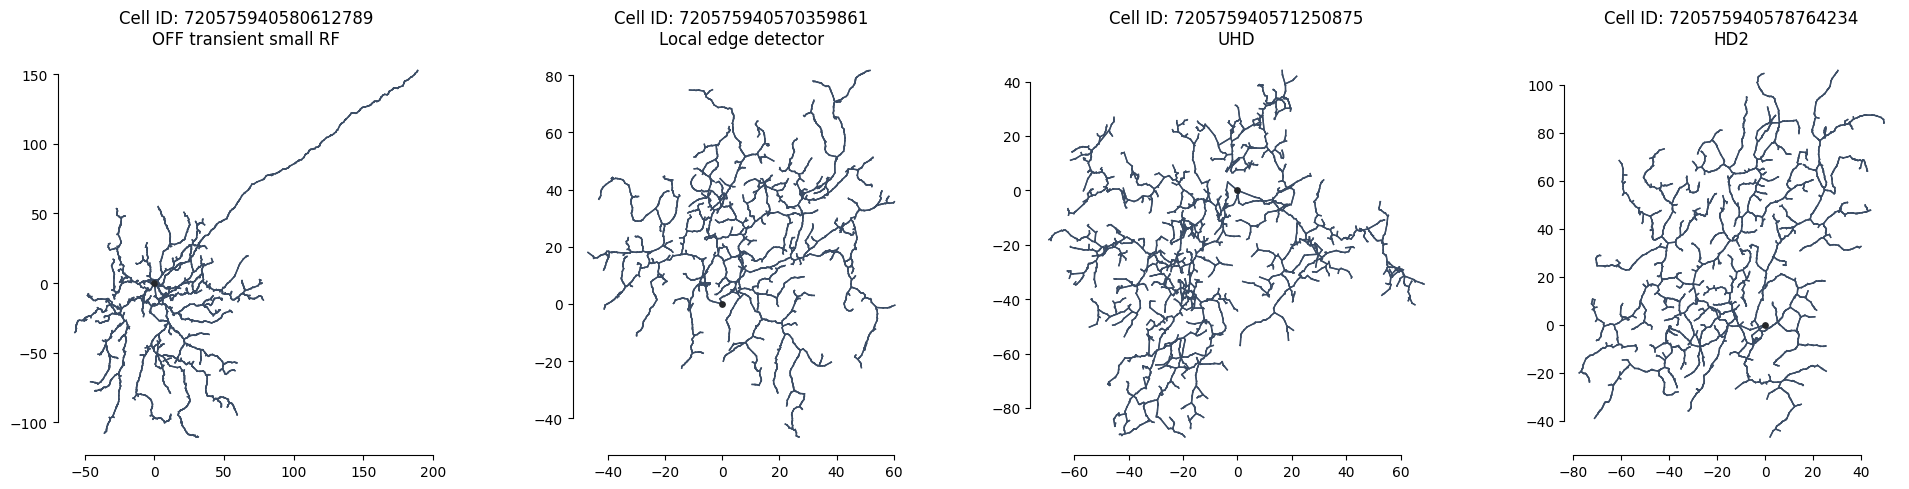

In [30]:
cell_ids = [
    720575940580612789,
    720575940570359861,
    720575940571250875,
    720575940578764234
]
fig, axes = plot_neurons(dset, cell_ids, merged_df)

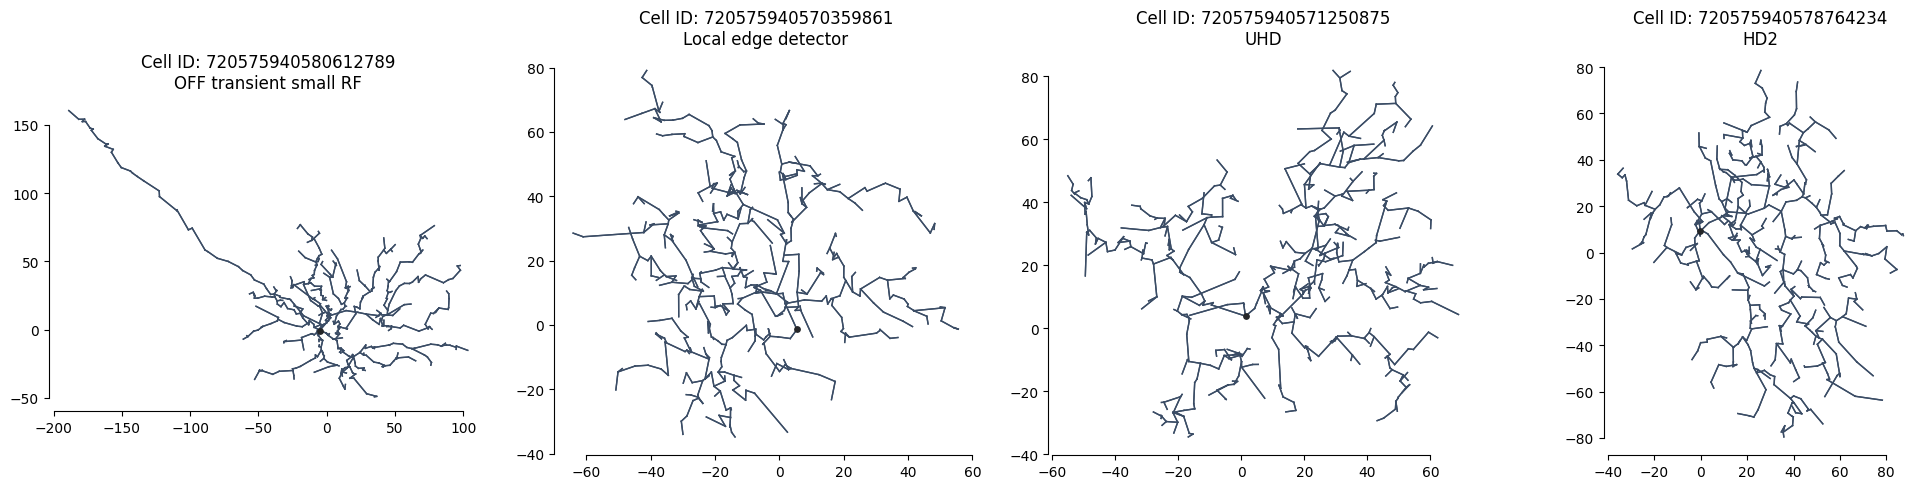

In [33]:
fig, axes = plot_neurons(dset, cell_ids, merged_df, augment=True)

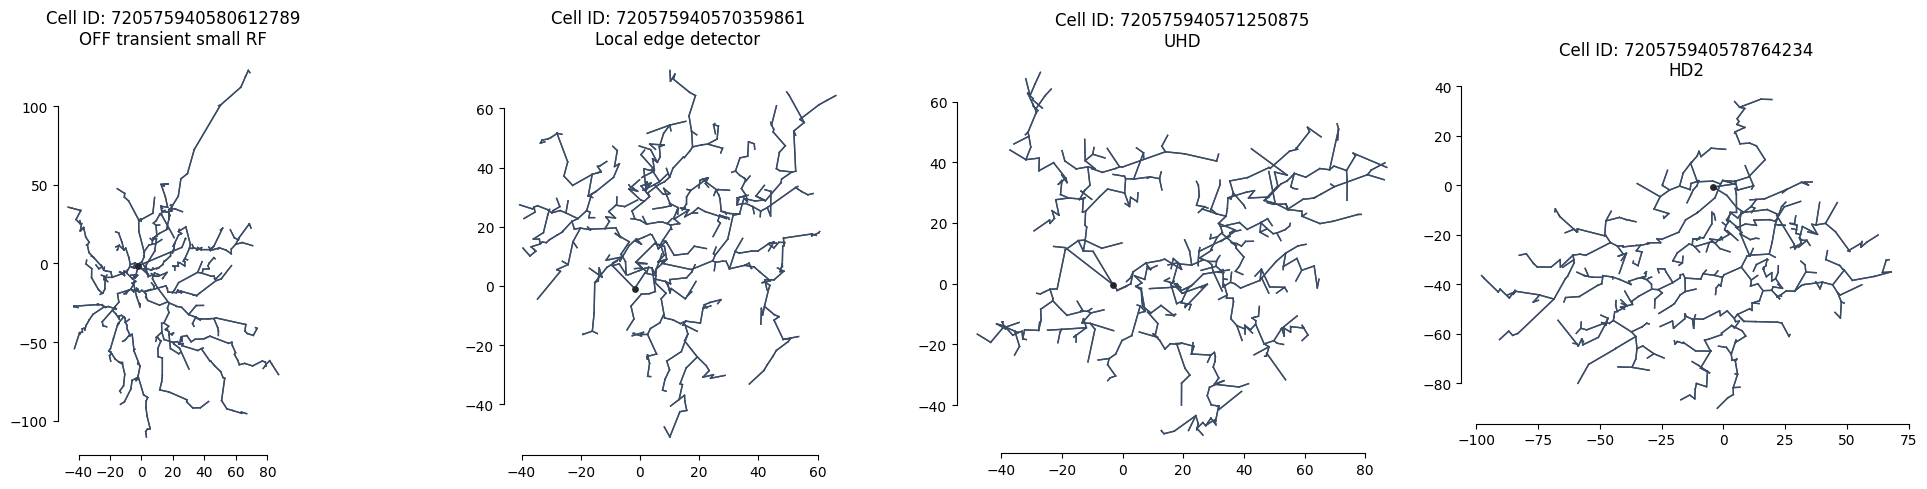

In [34]:
fig, axes = plot_neurons(dset, cell_ids, merged_df, augment=True)